# Per-cancer cfDNA metrics (Supplementary Figure 8)

Per-cancer cancer-vs-healthy and cancer-vs-other-cancers metrics (AP lift, AUC, balanced accuracy, F1) for the seven Cristiano tumor types. Metrics are computed per outer fold; bars show the mean and SEM across folds, and the dashed lines with shaded bands show the across-cancer mean with a bootstrap 95% CI.

Reads `../data/cfdna_mil_predictions.csv` and writes the figure to `../output/`. Source: `mil/mil_nested/cfdna_visualization/supp_cfdna_macro_performance_metrics.ipynb`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/jingz/leaf-1-figures/cfdna/data
OUT : /home/jingz/leaf-1-figures/cfdna/output


In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, balanced_accuracy_score, roc_curve)
from scipy.stats import bootstrap

SEED = 42
N_BOOTSTRAP = 10000
CANCERS = ['Bile_duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']
LABELS  = ['Bile duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']

def compute_max_f1(y_true, y_prob):
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    denom = precision + recall
    f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
    return np.max(f1)

def compute_balanced_accuracy_youden(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    best = np.argmax(tpr - fpr)
    return balanced_accuracy_score(y_true, (y_prob >= thr[best]).astype(int))

def compute_ap_lift(y_true, y_prob):
    prev = y_true.mean()
    return np.nan if prev == 0 else average_precision_score(y_true, y_prob)/prev

metric_fns = {
    'auc':     lambda yt, yp: roc_auc_score(yt, yp),
    'ap_lift': compute_ap_lift,
    'max_f1':  compute_max_f1,
    'bal_acc': compute_balanced_accuracy_youden,
}

df_raw = pd.read_csv(DATA/'cfdna_mil_predictions.csv')
df = df_raw.drop_duplicates(subset=['sample_id','task'], keep='first')
df = df[~df['true_group'].isin(['Duodenal_cancer','Unknown'])]

fold_rows = []
for cancer in CANCERS:
    for comparison in ['vs_healthy','vs_other_cancers']:
        task = f'{cancer}_cancer_{comparison}'
        tdf = df[df['task']==task]
        for fold, fdf in tdf.groupby('outer_fold'):
            yt = fdf['label'].values; yp = fdf['prob_ensemble'].values
            if len(np.unique(yt)) < 2:
                continue
            row = {'cancer': cancer, 'comparison': comparison}
            for m, fn in metric_fns.items():
                row[m] = fn(yt, yp)
            fold_rows.append(row)
fold_df = pd.DataFrame(fold_rows)

metric_names = ['auc','ap_lift','max_f1','bal_acc']
agg = []
for (cancer, comparison), g in fold_df.groupby(['cancer','comparison']):
    r = {'cancer': cancer, 'comparison': comparison}
    for m in metric_names:
        v = g[m].values
        r[f'{m}_mean'] = v.mean()
        r[f'{m}_sem']  = v.std()/np.sqrt(len(v))
    agg.append(r)
results_df = pd.DataFrame(agg)
print(results_df.round(3).to_string(index=False))

    cancer       comparison  auc_mean  auc_sem  ap_lift_mean  ap_lift_sem  max_f1_mean  max_f1_sem  bal_acc_mean  bal_acc_sem
 Bile_duct       vs_healthy     0.968    0.014        10.200        0.313        0.887       0.036         0.951        0.019
 Bile_duct vs_other_cancers     0.934    0.032         8.647        0.791        0.776       0.064         0.897        0.036
    Breast       vs_healthy     0.943    0.009         3.594        0.103        0.849       0.015         0.903        0.007
    Breast vs_other_cancers     0.871    0.044         2.567        0.253        0.777       0.056         0.829        0.038
Colorectal       vs_healthy     0.994    0.003        10.298        0.435        0.942       0.035         0.985        0.009
Colorectal vs_other_cancers     0.939    0.011         7.490        0.555        0.693       0.039         0.908        0.018
   Gastric       vs_healthy     0.965    0.023         9.988        0.523        0.941       0.022         0.957      

/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
  f1 = np.where(denom > 0, 2*precision*recall/denom, 0.0)
/tmp/ipykernel_3297338/2756272132.py:15: RuntimeWarning: invalid value encountered in divide
 

saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_per_cancer_metrics.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_per_cancer_metrics.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_per_cancer_metrics.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_per_cancer_metrics.tsv


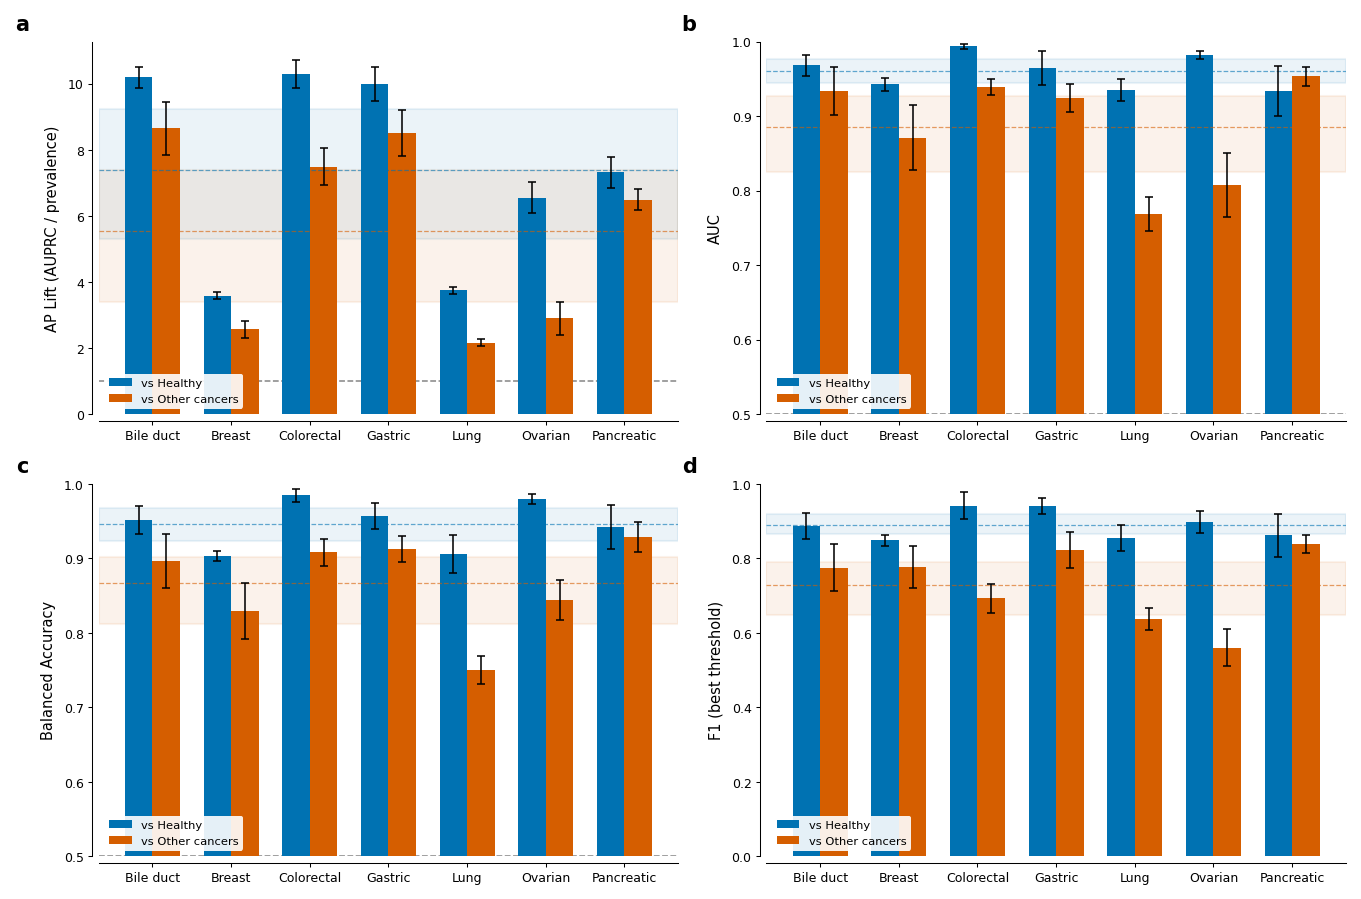

In [3]:
import matplotlib.pyplot as plt

def panel(ax, metric, ylabel, ylim, baseline):
    mc, sc = f'{metric}_mean', f'{metric}_sem'
    x = np.arange(len(CANCERS)); w = 0.35
    vh, sh, vo, so = [], [], [], []
    for cancer in CANCERS:
        for comp, vl, sl in [('vs_healthy', vh, sh), ('vs_other_cancers', vo, so)]:
            row = results_df[(results_df.cancer==cancer) & (results_df.comparison==comp)]
            vl.append(row[mc].values[0] if len(row) else np.nan)
            sl.append(row[sc].values[0] if len(row) else 0)
    if baseline is not None:
        ax.axhline(baseline, color='#888888', ls='--', lw=0.75, zorder=1)
    ax.bar(x-w/2, vh, w, yerr=sh, capsize=2, color=OKABE_ITO['blue'], label='vs Healthy',
           edgecolor='none', error_kw={'linewidth':0.75,'capthick':0.75}, zorder=2)
    ax.bar(x+w/2, vo, w, yerr=so, capsize=2, color=OKABE_ITO['orange'], label='vs Other cancers',
           edgecolor='none', error_kw={'linewidth':0.75,'capthick':0.75}, zorder=2)
    rng = np.random.default_rng(SEED)
    for arr, color in [(np.array(vh), OKABE_ITO['blue']), (np.array(vo), OKABE_ITO['orange'])]:
        valid = arr[~np.isnan(arr)]
        gm = valid.mean()
        ci = bootstrap((valid,), np.mean, n_resamples=N_BOOTSTRAP, confidence_level=0.95,
                       method='BCa', random_state=rng).confidence_interval
        ax.axhspan(ci.low, ci.high, color=color, alpha=0.08, zorder=0)
        ax.axhline(gm, color=color, ls='--', lw=0.6, alpha=0.6)
    ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=30, ha='right', fontsize=6)
    ax.set_ylabel(ylabel, fontsize=7)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.legend(loc='lower left', frameon=True, fontsize=5.5, facecolor='white',
              edgecolor='none', framealpha=0.9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward',3)); ax.spines['bottom'].set_position(('outward',3))
    ax.tick_params(axis='both', which='both', length=2, pad=2)

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
panel(axes[0,0], 'ap_lift', 'AP Lift (AUPRC / prevalence)', None,        1.0)
panel(axes[0,1], 'auc',     'AUC',                          (0.5, 1.0),  0.5)
panel(axes[1,0], 'bal_acc', 'Balanced Accuracy',            (0.5, 1.0),  0.5)
panel(axes[1,1], 'max_f1',  'F1 (best threshold)',          (0.0, 1.0),  None)
for ax, lab in zip(axes.ravel(), 'abcd'):
    ax.text(-0.12, 1.02, lab, transform=ax.transAxes, fontsize=10,
            fontweight='bold', va='bottom', ha='right')
plt.tight_layout()
savefig(fig, OUT, 'cfdna_per_cancer_metrics', data=(results_df))